# Case study: HCEA contact decay

How often two loci touch falls with their genomic distance. The shape of
that decay differs between cell types: some nuclei are rich in short-range
contacts (within domains and loops), others in long-range contacts (between
compartments, across chromosome territories). The Human Cell Epigenome Atlas
(HCEA; Zhou, Wu, Liu *et al.*) summarised each cell by the ratio of short-
(≈ 200 kb – 2 Mb) to long-range (≈ 10 – 100 Mb) contacts, and asked which
contacts carry the difference by splitting them by the compartment scores of
their two ends. This tutorial follows that analysis:

| Step | Function | HCEA |
|---|---|---|
| contact-distance histogram per cell | `epi.single.hic.contact_decay` | scHiCluster `hicluster contact-distance` |
| short/long ratio per cell | `epi.single.hic.decay_ratio` | published `Short/Long` |
| contacts by distance × compartment score | `epi.single.hic.compartment_contact_hist` | HCEA Fig. 4C |
| scores of all types on one distribution | `epi.single.hic.quantile_normalize` | `qnorm` |

The decay histograms and ratios reproduce HCEA's published values exactly
(`tests/parity/schicluster_decay/MANIFEST.md`).

**Data.** The 13,166 HCEA snm3C-seq nuclei of the compartment tutorial: the six
haematopoietic major types (memory T `c1`, myeloid `c0`, B `c7`, naive T `c15`,
mast `c24`, NK `c27`) from 15 tissues.

## 0 · Setup

In [1]:
import os
import pathlib
import warnings

import numpy as np
import pandas as pd
warnings.filterwarnings('ignore')     # before importing epione: silences tqdm's IProgress notice
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import seaborn as sns
from scipy.stats import zscore, pearsonr, spearmanr

import epione as epi
from epione.single import hic

epi.pl.plot_set()

DATA = pathlib.Path(os.environ.get('EPIONE_HCEA_DIR', 'data/hcea'))
FASTA = pathlib.Path(os.environ.get('EPIONE_HG38_FASTA', 'data/hg38/hg38.fa'))
OUT = pathlib.Path('result/t_sc_hic_decay')
OUT.mkdir(parents=True, exist_ok=True)
COMP_OUT = pathlib.Path('result/t_sc_hic_compartment')   # outputs of the compartment tutorial
NPROC = int(os.environ.get('EPIONE_NPROC', 16))

# chromosomes of HCEA's decay run: autosomes and chrX (no chrY)
fai = pd.read_csv(f'{FASTA}.fai', sep='\t', header=None, index_col=0)[1]
sizes = fai.loc[[f'chr{i}' for i in range(1, 23)] + ['chrX']]

files = sorted(DATA.glob('sc_contact/*/*.3C.contact.rmbkl.tsv.gz'))
cell_ids = [f.name.split('.3C.')[0] for f in files]
meta = pd.read_csv(DATA / 'metadata/5kCG100k3C_summary.csv.gz', index_col=0).loc[cell_ids]
L1_meta = pd.read_csv(DATA / 'metadata/L1color.tsv', sep='\t', index_col=0)
L1_annot = L1_meta['L1_abbr'].to_dict()
L1_color = L1_meta['color'].to_dict()
adata = hic.load_contact_tables(files, cell_ids=cell_ids, chrom_sizes=sizes,
                                obs=meta[['majortype', 'Tissue', 'mCGFrac', 'mCHFrac', 'Cis/Trans']])
adata

└─ 🔬 Starting plot initialization...
  ├─ Apply Scanpy/matplotlib settings
  ├─ Custom font setup
  ├─ Suppress warnings
  ├─ 
___________      .__                      
\_   _____/_____ |__| ____   ____   ____  
 |    __)_\____ \|  |/  _ \ /    \_/ __ \ 
 |        \  |_> >  (  <_> )   |  \  ___/ 
/_______  /   __/|__|\____/|___|  /\___  >
        \/|__|                  \/     \/ 

  ├─ 🔖 Version: 0.0.1rc1   📚 Tutorials: https://epione.readthedocs.io/
└─ ✅ plot_set complete.



AnnData object with n_obs × n_vars = 13166 × 0
    obs: 'contact_path', 'majortype', 'Tissue', 'mCGFrac', 'mCHFrac', 'Cis/Trans'
    uns: 'hic'

## 1 · Contact-distance histogram of every cell

`contact_decay` counts each cell's cis contacts in log2 distance bins of 1/8
that start at 2.5 kb (bin *k* covers 2.5 kb · 2^(k/8) to 2.5 kb · 2^((k+1)/8)),
as scHiCluster's `hicluster contact-distance`. It also returns the number of
distinct off-diagonal pixels per chromosome at 10 kb, a measure of how
sparse each cell is.

In [2]:
DECAY = OUT / 'decay.parquet'
if DECAY.exists():
    decay = pd.read_parquet(DECAY)
    decay.columns = decay.columns.astype(int)
else:
    decay, sparsity = hic.contact_decay(adata, nproc=NPROC, progress=False)
    decay.columns = decay.columns.astype(str)
    decay.to_parquet(DECAY)
    decay.columns = decay.columns.astype(int)
edges = hic.decay_bins(sizes)
print(f'{decay.shape[0]:,} cells × {decay.shape[1]} distance bins '
      f'({edges[0] / 1e3:.1f} kb – {edges[-1] / 1e6:.0f} Mb)')

13,166 cells × 132 distance bins (2.5 kb – 232 Mb)


HCEA published these histograms for all 86,689 atlas cells
(`analysis/decay/cell_*_decay.hdf5`). If they are present, the local cells
can be compared count by count.

In [3]:
pub_files = sorted((DATA / 'analysis/decay').glob('cell_*_decay.hdf5'))
if pub_files:
    pub = pd.concat([pd.read_hdf(f, key='data') for f in pub_files]).loc[decay.index]
    print('identical to the published histograms:', bool((pub.to_numpy() == decay.to_numpy()).all()))
else:
    print('published decay tables not found; skipping')

identical to the published histograms: True


## 2 · Short/long ratio

`decay_ratio` divides each histogram by its total and takes log2 of the mean
of the short-range bins (≈ 207 kb – 2.15 Mb) over the mean of the long-range
bins (≈ 10.1 – 107.6 Mb), HCEA's `Short/Long`.

In [4]:
adata.obs['short_long'] = hic.decay_ratio(decay).loc[adata.obs_names]
err = np.abs(adata.obs['short_long'] - meta['Short/Long']).max()
print(f'max difference from the published Short/Long: {err:.1e}')
adata.obs.groupby(adata.obs['majortype'].map(L1_annot))['short_long'].describe().round(3)

max difference from the published Short/Long: 4.4e-16


,count,mean,std,min,25%,50%,75%,max
majortype,,,,,,,,
Hema B,2000.0,-0.740,0.344,-3.805,-0.924,-0.721,-0.512,0.346
Hema Mast,1246.0,-0.797,0.313,-2.719,-0.980,-0.818,-0.654,0.439
Hema Myeloid,2588.0,-0.304,0.447,-3.560,-0.515,-0.291,-0.072,1.642
Hema NK,1073.0,-0.530,0.413,-3.880,-0.714,-0.454,-0.268,0.302
Hema Tmem,4344.0,-0.786,0.287,-2.676,-0.943,-0.767,-0.594,0.610
Hema Tnaive,1915.0,-0.522,0.153,-1.243,-0.606,-0.515,-0.424,-0.071


### Decay heatmap

Every column is a cell, every row a distance bin; colour is the z-score of the
cell's contact fraction across distances. Cells are grouped by major type
(ordered by median ratio) and sorted by their ratio within the type. Below:
major type, global CpG and non-CpG methylation, and the cis/trans ratio
(HCEA Fig. 4A).

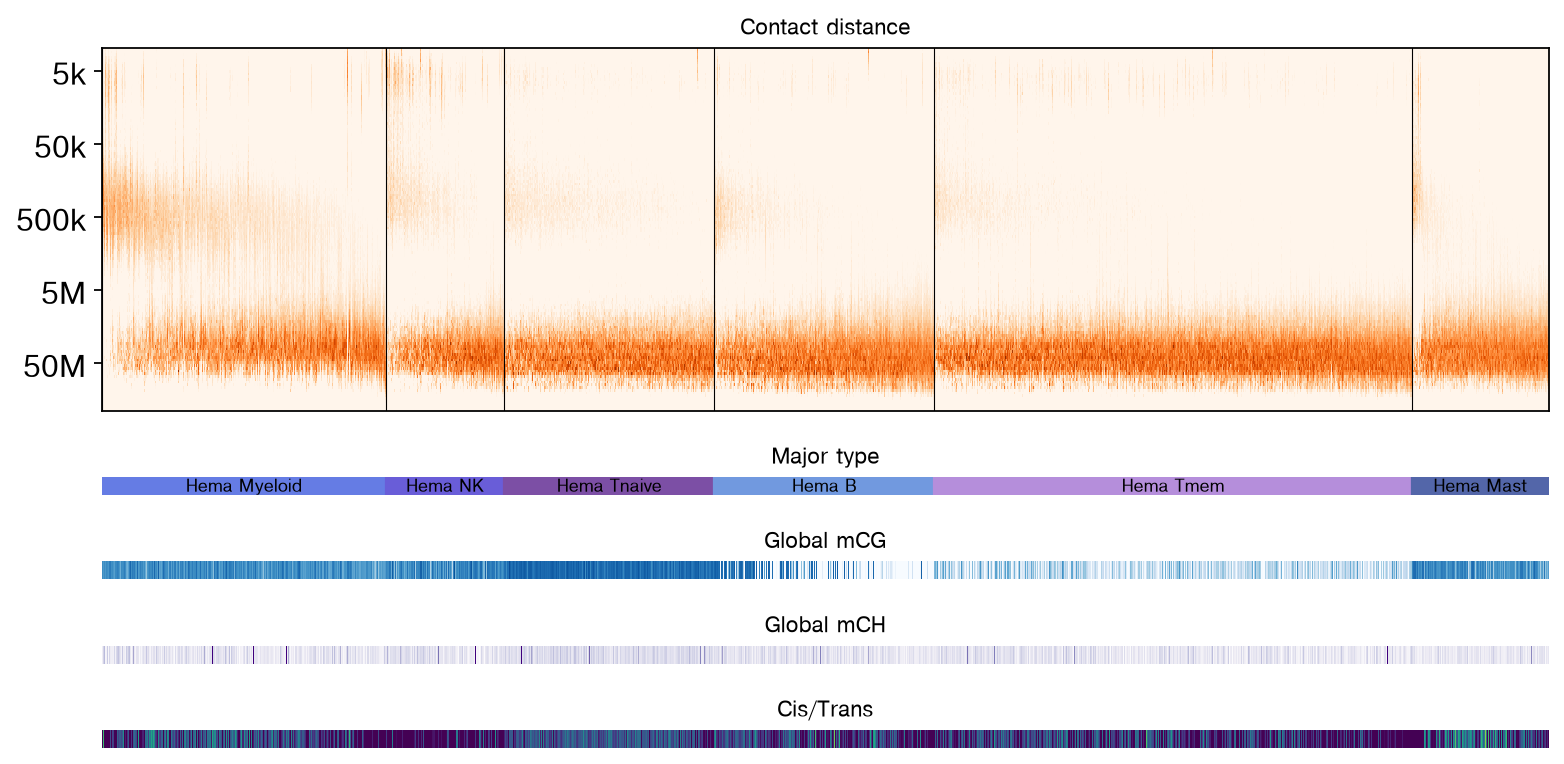

In [5]:
obs = adata.obs.copy()
leg = obs.groupby('majortype')['short_long'].median().sort_values().index[::-1]
order = np.concatenate([obs.index[obs['majortype'] == t][np.argsort(-obs.loc[obs['majortype'] == t, 'short_long'].to_numpy())]
                        for t in leg])
obs, d = obs.loc[order], decay.loc[order]
d = d / d.sum(axis=1).values[:, None]
offset = np.r_[0, np.cumsum([int((obs['majortype'] == t).sum()) for t in leg])]

fig, axes = plt.subplots(5, 1, height_ratios=[20, 1, 1, 1, 1], figsize=(10, 5), sharex=True)
axes[0].imshow(zscore(d.to_numpy(), axis=1).T, cmap='Oranges', vmin=0, vmax=4, aspect='auto',
               interpolation='none', rasterized=True)
ticks = [5e3, 5e4, 5e5, 5e6, 5e7]
axes[0].set_yticks([np.log2(x / 2500) / 0.125 for x in ticks])
axes[0].set_yticklabels(['5k', '50k', '500k', '5M', '50M'])
axes[0].set_xticks([])
for x in offset:
    axes[0].axvline(x - 0.5, color='k', lw=0.5)
axes[1].set_xlim(0, len(obs)); axes[1].set_ylim(0, 1); axes[1].axis('off')
for i, t in enumerate(leg):
    axes[1].add_patch(patches.Rectangle((offset[i], 0), offset[i + 1] - offset[i], 1, color=L1_color[t]))
    axes[1].text((offset[i] + offset[i + 1]) / 2, 0.5, L1_annot[t], ha='center', va='center', fontsize=8)
for ax, col, kw in [(axes[2], obs['mCGFrac'], dict(vmin=0.65, vmax=0.85, cmap='Blues')),
                    (axes[3], obs['mCHFrac'], dict(vmin=0.005, vmax=0.025, cmap='Purples')),
                    (axes[4], np.log2(obs['Cis/Trans']), dict(vmin=0, vmax=1.5, cmap='viridis'))]:
    ax.imshow(col.to_numpy()[None, :], aspect='auto', interpolation='none', rasterized=True, **kw)
    ax.axis('off')
for ax, title in zip(axes, ['Contact distance', 'Major type', 'Global mCG', 'Global mCH', 'Cis/Trans']):
    ax.set_title(title, fontsize=10)
plt.tight_layout(); plt.show()

### Ratio by type and tissue

The ratio separates the types. Within a type, the tissue the cell came
from shifts it too; the cis/trans ratio of a cell tracks its short/long ratio.

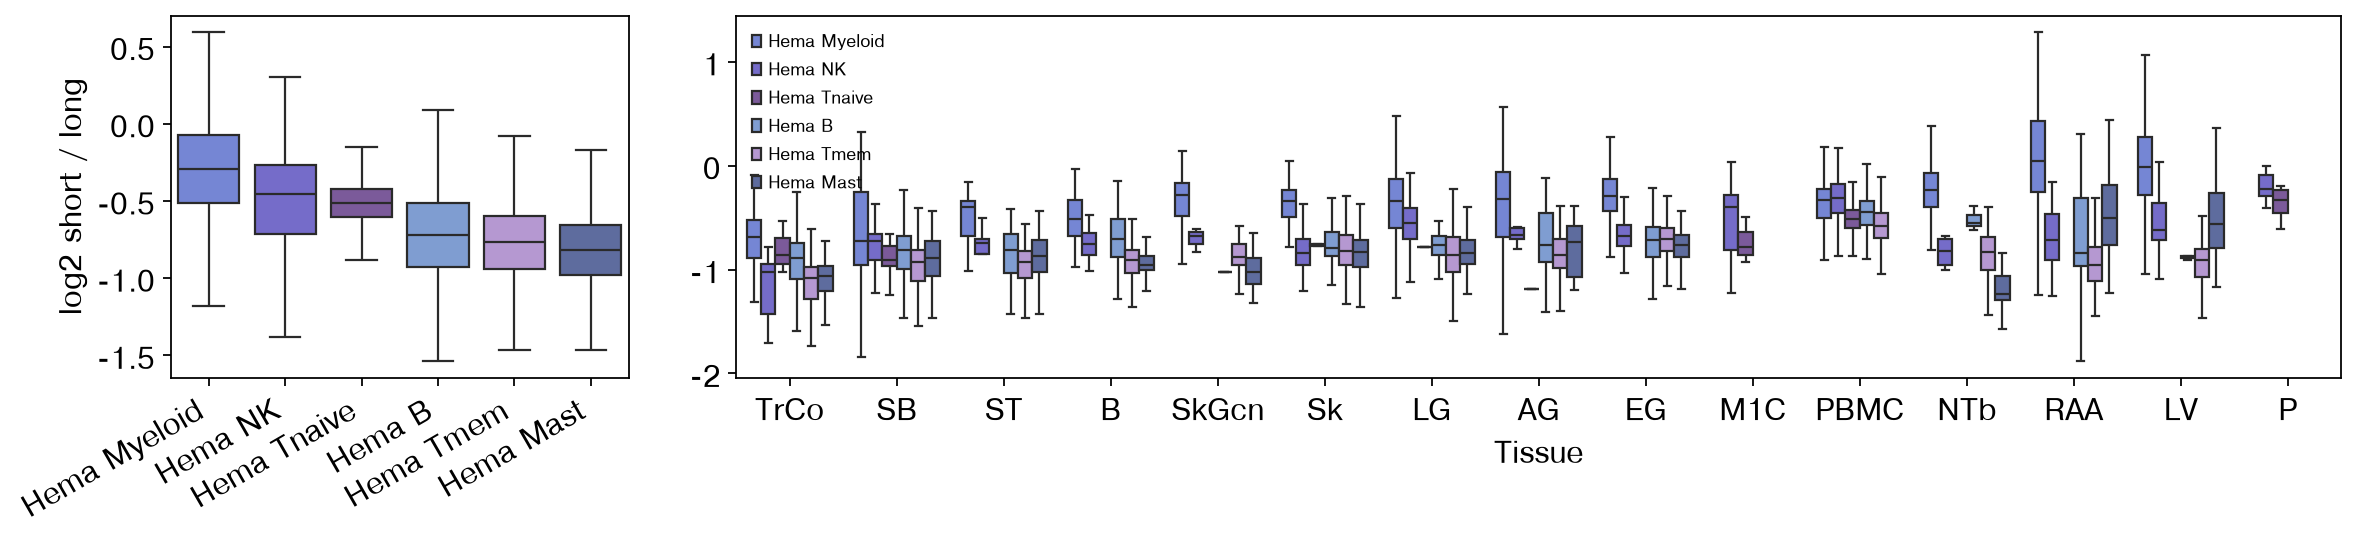

Pearson r(cis/trans, short/long) = 0.160


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), width_ratios=[1, 3.5])
sns.boxplot(data=adata.obs, x='majortype', y='short_long', order=leg, ax=axes[0], showfliers=False,
            palette=L1_color)
axes[0].set_xticklabels([L1_annot[t] for t in leg], rotation=30, ha='right')
axes[0].set_xlabel(''); axes[0].set_ylabel('log2 short / long')
tis = adata.obs.groupby('Tissue')['short_long'].median().sort_values().index
sns.boxplot(data=adata.obs, x='Tissue', y='short_long', hue='majortype', order=tis, hue_order=list(leg),
            palette=L1_color, ax=axes[1], showfliers=False)
axes[1].legend(handles=axes[1].get_legend_handles_labels()[0], labels=[L1_annot[t] for t in leg],
               frameon=False, fontsize=8)
axes[1].set_ylabel('')
plt.tight_layout(); plt.show()
r, p = pearsonr(adata.obs['Cis/Trans'], adata.obs['short_long'])
print(f'Pearson r(cis/trans, short/long) = {r:.3f}')

Myeloid cells have the most short-range contacts (median log2 ratio −0.29),
mast and memory T cells the fewest (−0.82 and −0.77), with NK (−0.45), naive
T (−0.52) and B cells (−0.72) in between. Within most tissues myeloid cells
still sit highest, so the difference is a property of the cell type; tissue
moves the ratio too (myeloid cells of the right atrium and liver are the
highest). Naive T cells, almost all from blood, are the most uniform (s.d.
0.15). The cis/trans ratio is only weakly related to the short/long ratio
(r ≈ 0.16).

### Ratio and compartmentalisation, cell by cell

HCEA compared the ratio of each major type with its compartment strength. We
also look cell by cell, using the per-cell strength from the compartment
tutorial (scHiCluster's AA, BB, AB sums).

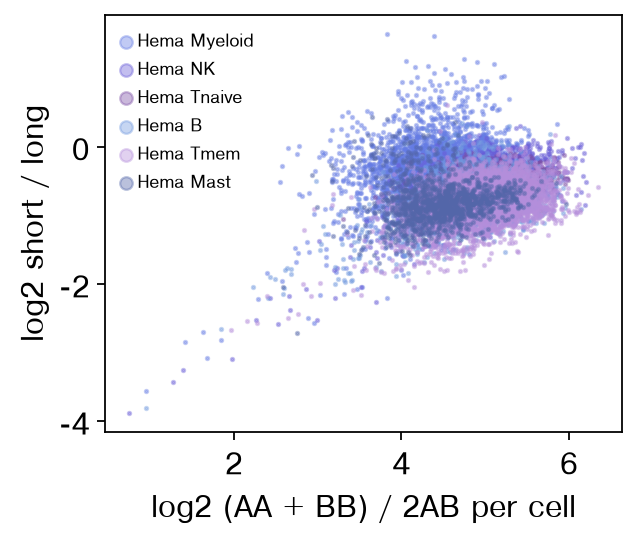

Spearman, all cells: 0.08
majortype
Hema Myeloid    0.199
Hema Tmem       0.283
Hema Tnaive     0.167
Hema Mast       0.110
Hema NK         0.432
Hema B          0.342
dtype: float64


In [7]:
SC = COMP_OUT / 'sc_compartment.h5ad'
if SC.exists():
    import anndata as ad
    st = ad.read_h5ad(SC).obsm['compartment_strength'].loc[adata.obs_names]
    adata.obs['comp_strength'] = np.log2((st['AA'] + st['BB']) / (2 * st['AB']))
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    for t in leg:
        o = adata.obs[adata.obs['majortype'] == t]
        ax.scatter(o['comp_strength'], o['short_long'], s=2, alpha=0.4, color=L1_color[t],
                   label=L1_annot[t], rasterized=True)
    ax.set_xlabel('log2 (AA + BB) / 2AB per cell'); ax.set_ylabel('log2 short / long')
    ax.legend(markerscale=4, frameon=False, fontsize=8)
    plt.tight_layout(); plt.show()
    print('Spearman, all cells:', round(spearmanr(adata.obs['comp_strength'], adata.obs['short_long']).correlation, 3))
    print(adata.obs.groupby('majortype').apply(
        lambda o: spearmanr(o['comp_strength'], o['short_long']).correlation).rename(L1_annot).round(3))
else:
    print('run t_sc_hic_compartment first for this section')

Within each type, cells with stronger compartments have relatively more
short-range contacts (Spearman 0.11–0.43, strongest in NK and B cells).
Pooled over all cells the relation almost vanishes (0.08), because the types
differ in both quantities.

## 3 · Which contacts carry the difference?

Every cis contact farther apart than 100 kb is placed by its distance and by
the compartment scores of its two ends: their absolute difference (small for
A–A and B–B, large for A–B) and their mean (high for A–A, low for B–B). Each
cell uses the score track of its own major type. HCEA first quantile-normalised
the scores of all types (`quantile_normalize`) so that a given difference
means the same in every type. HCEA used scores of imputed contacts; here they
are the raw-contact scores of the compartment tutorial.

In [8]:
COMP = COMP_OUT / 'comp.raw.tsv.gz'
if COMP.exists():
    comp = pd.read_csv(COMP, sep='\t')
else:   # same steps as t_sc_hic_compartment, sections 1-4
    scool = COMP_OUT / 'hcea_raw_100kb.scool'
    COMP_OUT.mkdir(parents=True, exist_ok=True)
    autos = sizes.iloc[:22]
    if not scool.exists():
        hic.contacts_to_scool(files, scool, chrom_sizes=autos, resolution=100_000, cell_ids=cell_ids, nproc=NPROC)
    cells = hic.load_scool_cells(scool, cell_names=cell_ids, obs=meta[['majortype']])
    cells.obs['merged'] = 'merged'
    pb = hic.merge_cells(cells, 'majortype', COMP_OUT / 'pseudobulk', cis_only=True, nproc=3)
    pb_all = hic.merge_cells(cells, 'merged', COMP_OUT / 'pseudobulk', cis_only=True)['merged']
    cpg = hic.cpg_ratio(FASTA, chrom_sizes=autos, resolution=100_000)
    comp = hic.project_compartments(pb, hic.compartment_model(pb_all, cpg), nproc=3)
types = [c for c in comp.columns if c not in ('chrom', 'start', 'end')]
comp_qn = comp.copy()
comp_qn[types] = hic.quantile_normalize(comp[types])
print(f'{len(comp):,} bins; score range after normalisation: '
      f'{comp_qn[types].min().min():.1f} to {comp_qn[types].max().max():.1f}')

24,647 bins; score range after normalisation: -13.5 to 15.5


In [9]:
HIST = OUT / 'compartment_contact_hist.npz'
if HIST.exists():
    z = np.load(HIST)
    hist = {t: {'diff': z[f'{t}_diff'], 'sum': z[f'{t}_sum']} for t in types}
else:
    hist = hic.compartment_contact_hist(adata, comp_qn, 'majortype', nproc=NPROC, progress=False)
    np.savez(HIST, **{f'{t}_{k}': hist[t][k] for t in types for k in ('diff', 'sum')})
pd.Series({L1_annot[t]: int(hist[t]['diff'].sum()) for t in types}, name='contacts counted')

Hema Myeloid    324537997
Hema Tmem       504553607
Hema Tnaive     211893223
Hema Mast       177619748
Hema NK         110743132
Hema B          243918167
Name: contacts counted, dtype: int64

Each panel shows, for every distance (rows), how a type's contacts are spread
over score differences (top) or score means (bottom), relative to all types
together (log2). Red: the type has more of its contacts there than the
average; white cells have fewer than 50 contacts.

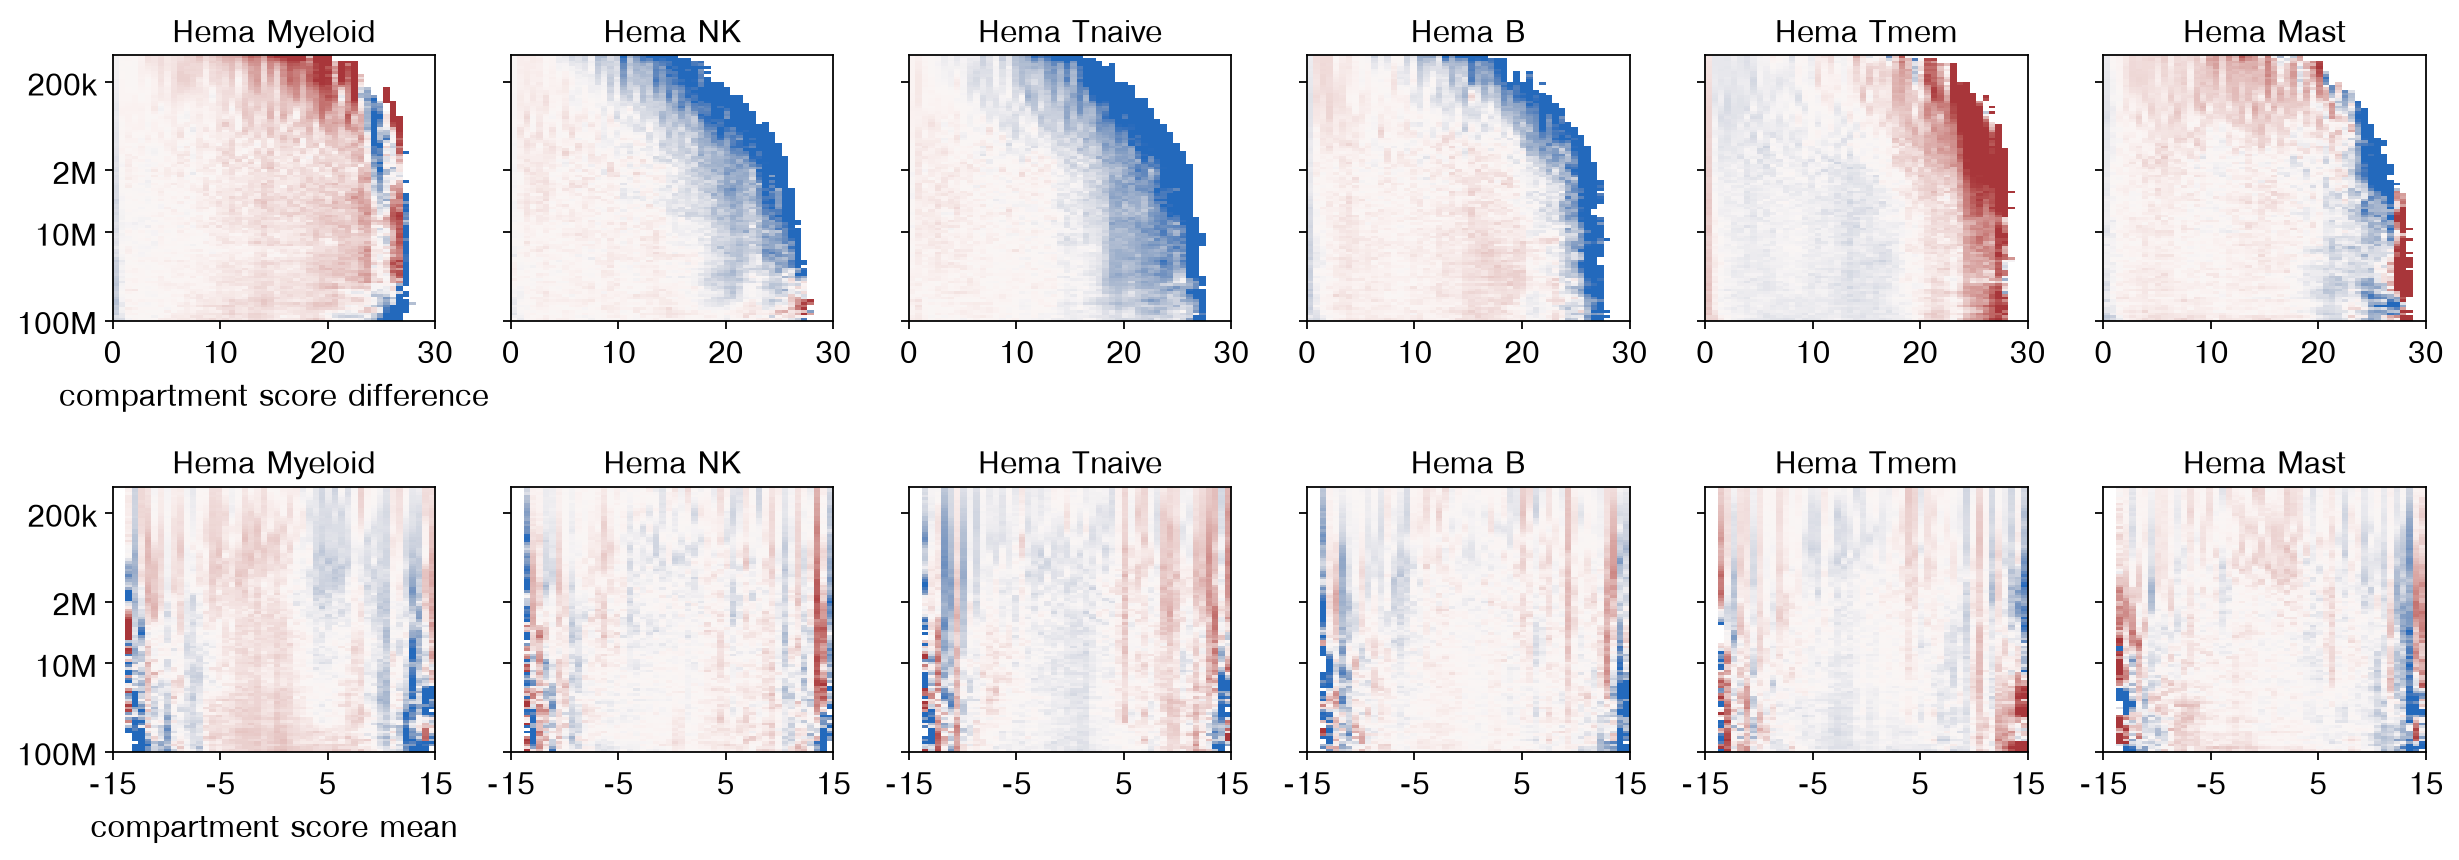

In [10]:
dist_t = (np.log10([2e5, 2e6, 1e7, 1e8]) - 5) * 100 / 3 - 0.5
dist_l = ['200k', '2M', '10M', '100M']

def rel(kind):
    ref = np.sum([hist[t][kind] for t in types], axis=0)
    ref = ref / ref.sum(axis=1, keepdims=True)
    out = {}
    for t in types:
        h = hist[t][kind] / hist[t][kind].sum(axis=1, keepdims=True)
        with np.errstate(divide='ignore', invalid='ignore'):
            r = np.log2(h / ref)
        r[hist[t][kind] < 50] = np.nan          # too few contacts to compare
        out[t] = r
    return out

order_t = [t for t in leg if t in types]
fig, axes = plt.subplots(2, len(order_t), figsize=(2.6 * len(order_t), 5.6), sharey=True)
for row, (kind, xt, xl, xlabel) in enumerate([
        ('diff', np.arange(0, 51, 50 / 3) - 0.5, [0, 10, 20, 30], 'compartment score difference'),
        ('sum', np.arange(0, 51, 50 / 3) - 0.5, [-15, -5, 5, 15], 'compartment score mean')]):
    r = rel(kind)
    for ax, t in zip(axes[row], order_t):
        cmap = plt.get_cmap('vlag').copy(); cmap.set_bad('white')
        ax.imshow(r[t], cmap=cmap, aspect='auto', interpolation='none', vmin=-1, vmax=1)
        ax.set_xticks(xt); ax.set_xticklabels(xl)
        ax.set_yticks(dist_t); ax.set_yticklabels(dist_l)
        ax.set_title(L1_annot[t]); ax.set_xlabel(xlabel if ax is axes[row, 0] else '')
plt.tight_layout(); plt.show()

At large score differences (A–B contacts, right side of the top row), memory
T cells have more contacts than the average of the six types at every
distance, while NK, naive T and B cells have fewer; myeloid and mast cells sit
in between. By the mean score (bottom row: B–B on the left, A–A on the right)
the types differ little.

The same contacts summed over a short (200 kb – 2 Mb) and a long (10 – 100 Mb)
window: the fraction of contacts at each score difference (left) and each
score mean, smoothed over 5 bins (right).

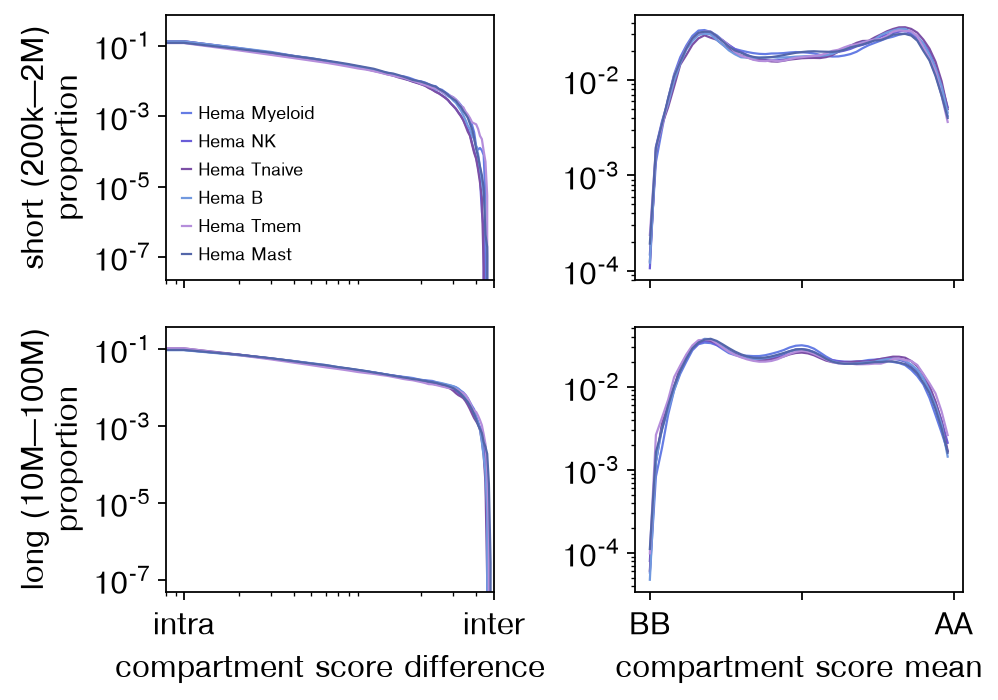

In [11]:
from scipy.signal import convolve
lo = np.around((np.log10([2e5, 1e7]) - 5) * 100 / 3).astype(int)
hi = np.around((np.log10([2e6, 1e8]) - 5) * 100 / 3).astype(int)
fig, axes = plt.subplots(2, 2, figsize=(6.4, 4.6), sharex='col')
for k in range(2):
    for t in order_t:
        h = hist[t]['diff'][lo[k]:hi[k]].sum(axis=0); h = h / h.sum()
        axes[k, 0].plot(np.arange(len(h)), h, color=L1_color[t], lw=1, label=L1_annot[t])
        s = hist[t]['sum'][lo[k]:hi[k]].sum(axis=0); s = s / s.sum()
        s = convolve(s, np.ones(5) / 5)[2:-2]
        axes[k, 1].plot(np.arange(len(s)), s, color=L1_color[t], lw=1)
    axes[k, 0].set_xscale('log'); axes[k, 0].set_xlim(0.8, 50)
    for ax in axes[k]:
        ax.set_yscale('log')
        ax.yaxis.set_minor_formatter(plt.NullFormatter())
    axes[k, 0].set_ylabel(['short (200k–2M)', 'long (10M–100M)'][k] + '\nproportion')
axes[1, 0].set_xticks([1, 50]); axes[1, 0].set_xticklabels(['intra', 'inter'])
axes[1, 0].set_xlabel('compartment score difference')
axes[1, 1].set_xticks([0, 25, 50]); axes[1, 1].set_xticklabels(['BB', '', 'AA'])
axes[1, 1].set_xlabel('compartment score mean')
axes[0, 0].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

## Summary

* `contact_decay` → `decay_ratio`: per-cell distance histograms and the
  short/long ratio, identical to HCEA's published values.
* `compartment_contact_hist` with `quantile_normalize`d cell-type scores:
  contacts split by distance and by the compartments they join.

Not covered: contacts around domain boundaries, which
needs domain calls; it comes with the domain tutorial.